# داده‌های با ابعاد بالا و نفرین ابعاد

**محمود امین‌طوسی، پاییز ۱۴۰۵**

گروه علوم کامپیوتر، دانشگاه فردوسی مشهد

واقعیت‌های هندسی این صفحه از *The Elements of Statistical Learning* ({cite}`hastie2009elements`),
بند 2.5، و فصل 6 کتاب *Data Mining and Machine Learning* زکی ({cite}`zaki2020data`) گرفته شده‌اند.

**اهداف یادگیری.** در پایان باید بتوانید

1. حجم کره و مکعب در $d$ بعد را حساب کنید و توضیح دهید چرا نسبتشان به صفر میل می‌کند؛
2. توضیح دهید چرا همسایگی‌ای که نسبتی ثابت از داده را در بر می‌گیرد در ابعاد بالا محلی نیست، و
   یال آن $e_d(r) = r^{1/d}$ را حساب کنید؛
3. نشان دهید در ابعاد بالا نزدیک‌ترین و دورترین همسایه تقریباً به یک اندازه دورند، و بگویید این
   برای k-NN چه معنایی دارد؛
4. توضیح دهید چرا بیشتر حجم کره در یک پوستهٔ نازک است، و چرا نمونه‌های گاوسی روی شعاع $\sqrt{d}$
   تمرکز می‌کنند؛
5. اثر بُعد را روی یک دسته‌بند k-NN، با و بدون دادهٔ بیشتر، اندازه بگیرید.
6. صورت لم جانسون–لیندن‌شتراوس را بیان کنید و بگویید چرا همان تمرکز فاصله‌ها آن را ممکن می‌کند.

<div class="langswitch">
  <a href="#lang-en">English</a> · <strong>فارسی</strong>
</div>

## مقدمه

در یادگیری ماشین امروزی اغلب با داده در فضاهای با ابعاد بالا سر و کار داریم (تصویر، نمایش برداری
متن، دادهٔ ژنومی). یک مجموعه‌داده معمولاً به‌صورت ماتریس $n \times d$ نمایش داده می‌شود: $n$ نقطه و
$d$ ویژگی.

فضای با ابعاد بالا، یا **اَبَرفضا**، مثل هندسهٔ دو یا سه بعد رفتار نمی‌کند. مجموعهٔ اثرهایی که از
این واقعیت برمی‌آید **نفرین ابعاد** نامیده می‌شود. در مقدمهٔ درس این پدیده‌ها فقط نام برده شدند؛
اینجا هر یک را با محاسبه اندازه می‌گیریم:

1. **تمرکز حجم**: حجم ابرکره در برابر ابرمکعبی که آن را در بر دارد ناچیز می‌شود.
2. **مسئلهٔ همسایگی‌های محلی**: همسایگی «محلی»ای که نسبتی ثابت از داده را در بر می‌گیرد دیگر محلی
   نیست، پس روش‌هایی مثل k-NN معنای خود را از دست می‌دهند (ESL بند 2.5).
3. **تمرکز فاصله**: نزدیک‌ترین و دورترین همسایه تقریباً در یک فاصله‌اند، پس رتبه‌بندی همسایه‌ها
   بی‌معنا می‌شود.
4. **پوستهٔ نازک و رفتار گاوسی**: تقریباً همهٔ حجم کره نزدیک سطح آن است و نمونه‌های گاوسی روی
   شعاع $\sqrt{d}$ متمرکز می‌شوند.

در سراسر این صفحه $d$ تعداد ابعاد است. شکل‌هایی که از ESL آمده‌اند آن را $p$ می‌نامند؛ متن اینجا
به‌طور یکدست $d$ به کار می‌برد.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np

SEED = 42
rng = np.random.default_rng(SEED)


def ball_volume(d, r=1.0):
    # Volume of the d-dimensional ball of radius r: K_d * r^d.
    return math.pi ** (d / 2) * r ** d / math.gamma(d / 2 + 1)


def shell_volume(d, r=1.0, thickness=0.2):
    # Volume of the shell of the given thickness just inside the surface.
    return ball_volume(d, r) - ball_volume(d, max(r - thickness, 0.0))

## هندسهٔ اَبَرفضا: مکعب‌ها و کره‌ها

### ابرمکعب، کره و سطح کره

ابرکعب $H_d(l)$ با یال $l$ حجم

$$
\operatorname{Vol}\big(H_d(l)\big) = l^d
$$

دارد، در حالی که حجم کرهٔ توپر $B_d(r) = \{\mathbf{x} : \|\mathbf{x}\| \le r\}$ 

$$
\operatorname{Vol}\big(B_d(r)\big) = K_d\, r^d,
\qquad
K_d = \frac{\pi^{d/2}}{\Gamma\!\left(\frac{d}{2}+1\right)}
$$

است. **سطح** کره $S^{d-1}(r) = \{\mathbf{x} : \|\mathbf{x}\| = r\}$ شیئی $(d-1)$-بعدی و مجموعه‌ای با
اندازهٔ صفر است؛ مساحتش $d K_d r^{d-1}$، یعنی مشتق حجم نسبت به $r$. اشتباه گرفتن این دو منبع
کلاسیک خطاست. ($\Gamma$ تابع گاما است و برای آرگومان‌های صحیح $\Gamma(m) = (m-1)!$.)

![](img/Figure-6.4-Zaki.png)

*شکل 6.4. ابرکره‌ای محاط در ابرمکعب در (الف) دو و (ب) سه بعد (زکی، فصل 6).*

### مرکز تهی (اثر «خارپشت»)

برای بزرگ‌ترین کره‌ای که در مکعبی با یال $l = 2r$ جا می‌شود، نسبت حجم‌ها

$$
\frac{\operatorname{Vol}\big(B_d(r)\big)}{\operatorname{Vol}\big(H_d(2r)\big)}
= \frac{\pi^{d/2}}{2^d\,\Gamma\!\left(\frac{d}{2}+1\right)}
\;\xrightarrow[d \to \infty]{}\; 0
$$

است. **پیامد.** با رشد بُعد کره در برابر مکعب ناچیز می‌شود: تقریباً همهٔ حجم مکعب در **گوشه‌های**
آن ($2^d$ گوشه) است و مرکز عملاً تهی است.

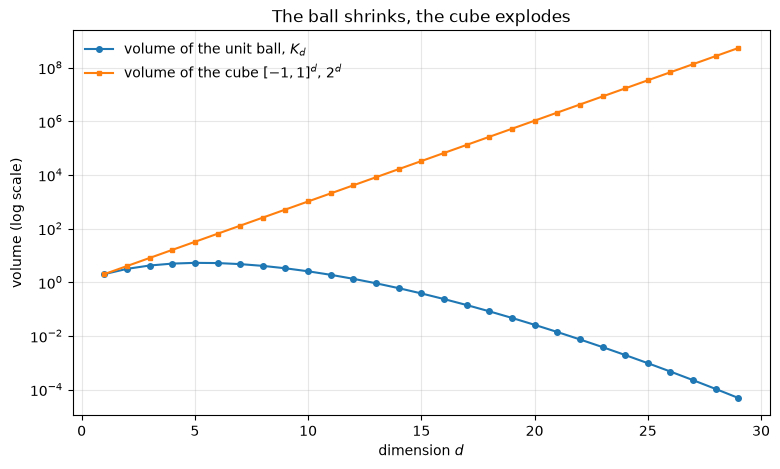

d =  2:  ratio ball/cube = 7.854e-01
d = 10:  ratio ball/cube = 2.490e-03
d = 20:  ratio ball/cube = 2.461e-08


In [2]:
dimensions = list(range(1, 30))
plt.figure(figsize=(9, 5))
plt.plot(dimensions, [ball_volume(d) for d in dimensions], marker="o", ms=4,
         label=r"volume of the unit ball, $K_d$")
plt.plot(dimensions, [2.0 ** d for d in dimensions], marker="s", ms=3,
         label=r"volume of the cube $[-1,1]^d$, $2^d$")
plt.yscale("log")
plt.xlabel("dimension $d$")
plt.ylabel("volume (log scale)")
plt.title("The ball shrinks, the cube explodes")
plt.legend(frameon=False)
plt.grid(alpha=0.3)
plt.show()

for d in [2, 10, 20]:
    print(f"d = {d:2d}:  ratio ball/cube = {ball_volume(d) / 2 ** d:.3e}")

## مسئلهٔ همسایگی‌های محلی

روش‌های «محلی» مثل k نزدیک‌ترین همسایه در ابعاد بالا دیگر محلی نیستند. فرض کنید ورودی‌ها به‌طور
یکنواخت در ابرمکعب یکه $[0,1]^d$ پخش شده‌اند و همسایگی‌ای می‌خواهیم که نسبت $r$ از مشاهدات را در
بر گیرد. آن همسایگی باید نسبت $r$ از حجم را بپوشاند، پس اگر زیرمکعبی با یال $e_d(r)$ باشد

$$
\big(e_d(r)\big)^d = r
\qquad\Longrightarrow\qquad
e_d(r) = r^{1/d} .
$$

![](img/Figure-2.6-ESL.png)

*شکل 2.6 (ESL). یال زیرمکعبی که برای در برگرفتن نسبتی از حجم داده لازم است، در ابعاد مختلف
(شکل بُعد را $p$ می‌نامد؛ اینجا $d$ است).*

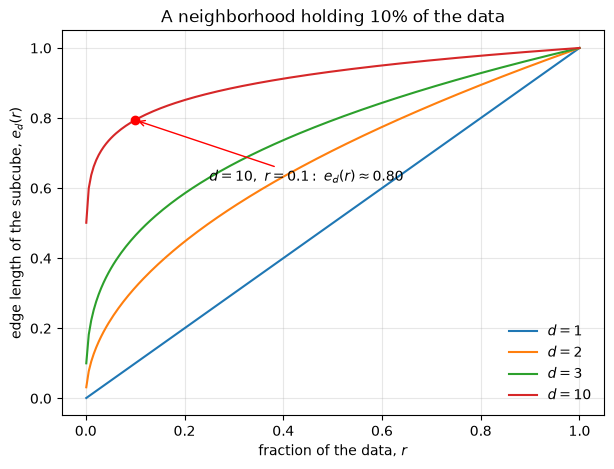

In [3]:
def edge_length(fraction, d):
    return fraction ** (1.0 / d)


fractions = np.linspace(0.001, 1.0, 200)
plt.figure(figsize=(7, 5))
for d in [1, 2, 3, 10]:
    plt.plot(fractions, edge_length(fractions, d), label=f"$d={d}$")

plt.plot(0.1, 0.1 ** (1 / 10), "ro")
plt.annotate(r"$d=10,\ r=0.1:\ e_d(r)\approx 0.80$", (0.1, 0.1 ** (1 / 10)),
             xytext=(0.25, 0.62), arrowprops=dict(arrowstyle="->", color="red"))
plt.xlabel(r"fraction of the data, $r$")
plt.ylabel(r"edge length of the subcube, $e_d(r)$")
plt.title("A neighborhood holding 10% of the data")
plt.legend(frameon=False)
plt.grid(alpha=0.3)
plt.show()

**تحلیل.** با $d = 10$ و $r = 0.1$ به $e_{10}(0.1) = 0.1^{0.1} \approx 0.80$ نیاز داریم: برای
گرفتن 10٪ داده باید **80٪ دامنهٔ هر مؤلفه** را بپوشانیم. چنین همسایگی‌ای به هیچ معنای سودمندی محلی
نیست — تقریباً همهٔ فضا است.

### فاصله تا مرز

عیب دومی هم هست. برای $N$ نقطهٔ یکنواخت در کرهٔ یکه، میانهٔ فاصلهٔ مبدأ تا نزدیک‌ترین نقطهٔ داده

$$
d(d, N) = \left(1 - \left(\tfrac{1}{2}\right)^{1/N}\right)^{1/d}
$$

است: احتمال بیرون افتادن همهٔ $N$ نقطه از کره‌ای به شعاع $t$ برابر $(1 - t^d)^N$ است و میانه همان
$t$ی است که این احتمال را $1/2$ می‌کند. با $N = 500$ و $d = 10$ مقدار $\approx 0.52$ به دست
می‌آید، یعنی بیش از نیمهٔ راه تا مرز: **بیشتر نقطه‌های داده به مرز فضای نمونه نزدیک‌ترند تا به هر
نقطهٔ دادهٔ دیگر**، و پیش‌بینی مسئلهٔ *برون‌یابی* است نه درون‌یابی.

## تمرکز فاصله

پدیده‌ای که بیش از همه به k-NN آسیب می‌زند خود فاصله‌هاست. برای یک نقطهٔ پرس‌وجو، $d_{\min}$ را
فاصله تا نزدیک‌ترین همسایه و $d_{\max}$ را فاصله تا دورترین نقطهٔ نمونه بگیرید. در یک بعد نسبت
$d_{\min}/d_{\max}$ کوچک است؛ در ابعاد بالا به $1$ میل می‌کند، پس «نزدیک‌ترین» گزاره‌ای دربارهٔ
نوفه است نه دربارهٔ شباهت.

آزمایش زیر $n$ نقطه را به‌طور یکنواخت در مکعب یکه برای $d = 2, 10, 100, 1000$ می‌ریزد و میانگین
نسبت $d_{\min}/d_{\max}$ را روی پرس‌وجوهای تصادفی گزارش می‌کند.

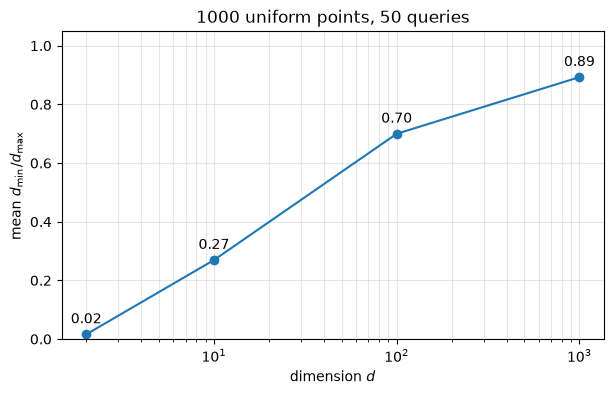

d =    2:  mean d_min/d_max = 0.016
d =   10:  mean d_min/d_max = 0.269
d =  100:  mean d_min/d_max = 0.700
d = 1000:  mean d_min/d_max = 0.893


In [4]:
n_points, n_queries = 1000, 50
dims_dc = [2, 10, 100, 1000]
ratios = []

for d in dims_dc:
    data = rng.random((n_points, d))
    queries = rng.random((n_queries, d))
    dist = np.linalg.norm(queries[:, None, :] - data[None, :, :], axis=2)
    ratios.append(np.mean(dist.min(axis=1) / dist.max(axis=1)))

plt.figure(figsize=(7, 4))
plt.plot(dims_dc, ratios, marker="o")
for x, y in zip(dims_dc, ratios):
    plt.annotate(f"{y:.2f}", (x, y), textcoords="offset points", xytext=(0, 8), ha="center")
plt.xscale("log")
plt.xlabel("dimension $d$")
plt.ylabel(r"mean $d_{\min}/d_{\max}$")
plt.title(f"{n_points} uniform points, {n_queries} queries")
plt.ylim(0, 1.05)
plt.grid(alpha=0.3, which="both")
plt.show()

for d, ratio in zip(dims_dc, ratios):
    print(f"d = {d:4d}:  mean d_min/d_max = {ratio:.3f}")

عددها را بخوانید: در دو بعد نزدیک‌ترین همسایه کسر کوچکی از دورترین فاصله است، پس رتبه‌بندی
همسایه‌ها آگاهی‌بخش است؛ در هزار بعد نسبت نزدیک $1$ است — **هر نقطه تقریباً از هر نقطهٔ دیگر
هم‌فاصله است**. دو پیامد:

* رتبه‌بندی همسایه‌ها زیر سلطهٔ نوفه است: اینکه کدام نقطه «نزدیک‌ترین» است با اغتشاش‌های کوچک داده
  عوض می‌شود، پس رأی k-NN ناپایدار است.
* کره‌ای حول پرس‌وجو که $k$ همسایه را در بر می‌گیرد چنان بزرگ است که بخش خوبی از داده را شامل
  می‌شود، پس میانگین «محلی» محلی نیست.

این همان دلیل نظری پشت آزمایش پایان این صفحه است.

## استدلال پوستهٔ نازک

حجم داخل کره کجاست؟ برای پوستهٔ نازکی با ضخامت $\epsilon$ درست زیر سطح کرهٔ شعاع $r$،

$$
\operatorname{Vol}\big(B_d(r)\big) - \operatorname{Vol}\big(B_d(r-\epsilon)\big)
= K_d\left(r^d - (r-\epsilon)^d\right),
$$

پس نسبت حجمی که در پوسته است

$$
\frac{\operatorname{Vol}(\text{shell})}{\operatorname{Vol}\big(B_d(r)\big)}
= 1 - \left(1 - \frac{\epsilon}{r}\right)^{d}
\;\xrightarrow[d\to\infty]{}\; 1 .
$$

![](img/Figure-6.6-Zaki.png)

*شکل 6.6 (زکی، فصل 6): پوستهٔ کره حجم را با رشد $d$ در خود جمع می‌کند.*

> برای قرصی ($d=2$) با $r=1$ و $\epsilon=0.01$ پوسته $1-0.99^2 \approx 2\%$ از مساحت را دارد.
> برای $d=100$ همان پوسته $1-0.99^{100} \approx 0.63$ — نزدیک دو سوم.

**نتیجه.** در ابعاد بالا، برای پوسته‌ای با ضخامت نسبی ثابت، تقریباً **100٪ حجم** نزدیک سطح متمرکز
است و درون آن عملاً تهی است. همین اثر نمونه‌برداری ردکردنی (تولید نقطه در مکعب و نگه‌داشتن
نقطه‌های داخل کره) را در ابعاد بالا بی‌فایده می‌کند: نرخ پذیرش مثل $K_d/2^d$ به صفر می‌رود. راه
درست، ضرب یک جهت گاوسی در شعاع $a^{1/d}$ با $a \sim U(0,1)$ است.

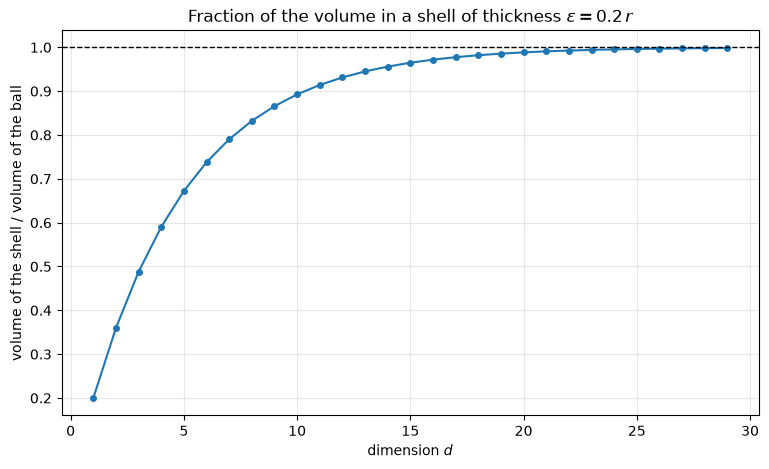

d =  2:  shell fraction = 0.360
d = 10:  shell fraction = 0.893
d = 30:  shell fraction = 0.999


In [5]:
dims_shell = list(range(1, 30))
fraction = [shell_volume(d, 1.0, 0.2) / ball_volume(d, 1.0) for d in dims_shell]

plt.figure(figsize=(9, 5))
plt.plot(dims_shell, fraction, marker="o", ms=4)
plt.axhline(1.0, color="black", lw=1, ls="--")
plt.xlabel("dimension $d$")
plt.ylabel(r"volume of the shell / volume of the ball")
plt.title(r"Fraction of the volume in a shell of thickness $\epsilon = 0.2\,r$")
plt.grid(alpha=0.3)
plt.show()

for d in [2, 10, 30]:
    print(f"d = {d:2d}:  shell fraction = {shell_volume(d, 1.0, 0.2) / ball_volume(d, 1.0):.3f}")

## توزیع گاوسی در ابعاد بالا

### از پوستهٔ هندسی به پوستهٔ آماری

اثرهای بالا دربارهٔ حجم کره بودند؛ توزیع گاوسی همان پدیده را آماری نشان می‌دهد. برای
$\mathbf{x} \sim \mathcal{N}(0, I_d)$

$$
\|\mathbf{x}\|^2 = \sum_{i=1}^d x_i^2 \sim \chi^2_d,
\qquad
\mathbb{E}\|\mathbf{x}\|^2 = d,
\qquad
\mathbb{E}\|\mathbf{x}\| \approx \sqrt{d} .
$$

چگالی در مبدأ بیشینه است ولی **حجم** موجود نزدیک مبدأ ناچیز: در یک بعد «مرکز» یک نقطه است و رشد
حجمی وجود ندارد، ولی در $d$ بعد تعداد نقطه‌های روی شعاع $r$ متناسب با $r^{d-1}$ است. پس
$\|\mathbf{x}\| \approx 0.8$ برای $d=1$، $\approx 3.16$ برای $d=10$ و $\approx 14.1$ برای
$d=200$: افزودن بُعد **همهٔ** نمونه‌ها را به بیرون می‌راند و کل توزیع در پوستهٔ نازکی حول
$\sqrt{d}$ می‌نشیند که ضخامتش با $d$ رشد نمی‌کند.

### تعامد تقریبی

همین تمرکز توضیح می‌دهد چرا بردارهای تصادفی تقریباً متعامدند. برای $\mathbf{x}$ و $\mathbf{y}$ با
مؤلفه‌های مستقل، میانگین صفر و واریانس یک،

$$
\frac{\mathbf{x}^\top \mathbf{y}}{\|\mathbf{x}\|\,\|\mathbf{y}\|}
\approx \frac{\sum_i x_i y_i}{d}
= O\!\left(1/\sqrt{d}\right)
\;\xrightarrow[d\to\infty]{}\; 0,
$$

چون صورت مجموع $d$ جملهٔ مستقل با میانگین صفر و واریانس $1$ و بنابراین به اندازهٔ $\sqrt{d}$ است،
و مخرج $d$. به همین ترتیب قطر ابرمکعب $\mathbf{1}$ با هر محور زاویهٔ $\cos\theta_d = 1/\sqrt{d}$
می‌سازد که به $90^\circ$ میل می‌کند.

نکتهٔ قوی‌تر این است که کسینوس فقط **به‌طور میانگین** صفر نیست، بلکه **متمرکز** است: صورت با
پراکندگی $\sqrt{d}$ حول صفر می‌نوساند و مخرج تقریباً $d$ است (چون
$\|\mathbf{x}\| \approx \|\mathbf{y}\| \approx \sqrt{d}$)، پس

$$
\cos\theta \;\sim\; \mathcal{N}\!\left(0,\; \tfrac{1}{d}\right),
\qquad
\Pr\!\left(|\cos\theta| > \varepsilon\right) \;\le\; 2e^{-d\varepsilon^2/2}.
$$

یعنی در $d = 1000$ تقریباً همهٔ جفت‌بردارها زاویه‌ای بین $88^\circ$ و $92^\circ$ می‌سازند و
تنها کسر ناچیزی بیرون این بازه می‌افتند: متعامد بودن در ابعاد بالا **حالت عمومی** است، نه
استثنا. این با هندسهٔ دو بعدی که در آن دو جهت تصادفی معمولاً زاویهٔ دلخواه دارند فرق دارد، و با
تعامد دقیق هم یکی نیست: در دو بعد بیش از دو بردار دوبه‌دو متعامد وجود ندارد، در $d$ بعد می‌توان
$d$ بردار داشت، و بردارهای تصادفی به‌طور فزاینده به همین حالت نزدیک می‌شوند.

این تعامد تقریبی همان چیزی است که در بخش بعد به کار می‌آید: اگر جهت‌ها به‌طور تصادفی تقریباً
متعامد و طول‌ها تقریباً هم‌اندازه باشند، هندسهٔ نقطه‌ها زیر یک نگاشت تصادفی چندان به‌هم نمی‌ریزد.


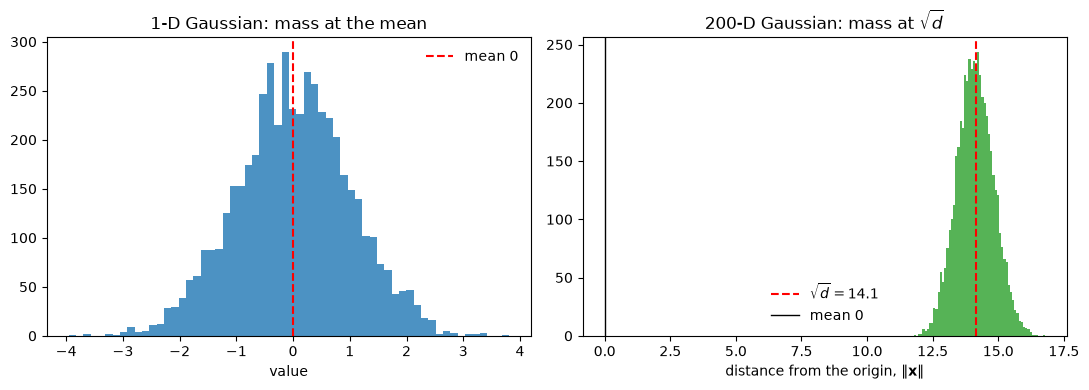

mean norm = 14.12   std = 0.70   sqrt(d) = 14.14


In [6]:
d_gauss = 200
n_gauss = 5000

x_1d = rng.standard_normal(n_gauss)
norms = np.linalg.norm(rng.standard_normal((n_gauss, d_gauss)), axis=1)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(x_1d, bins=60, color="tab:blue", alpha=0.8)
ax[0].axvline(0, color="red", ls="--", label="mean 0")
ax[0].set_title("1-D Gaussian: mass at the mean")
ax[0].set_xlabel("value")
ax[0].legend(frameon=False)

ax[1].hist(norms, bins=60, color="tab:green", alpha=0.8)
ax[1].axvline(np.sqrt(d_gauss), color="red", ls="--",
              label=rf"$\sqrt{{d}} = {np.sqrt(d_gauss):.1f}$")
ax[1].axvline(0, color="black", lw=1, label="mean 0")
ax[1].set_title(rf"{d_gauss}-D Gaussian: mass at $\sqrt{{d}}$")
ax[1].set_xlabel(r"distance from the origin, $\|\mathbf{x}\|$")
ax[1].legend(frameon=False)
plt.tight_layout()
plt.show()

print(f"mean norm = {norms.mean():.2f}   std = {norms.std():.2f}   sqrt(d) = {np.sqrt(d_gauss):.2f}")

این دو بافت‌نگار نسخهٔ آماری اثر هندسی پوستهٔ نازک‌اند: دادهٔ گاوسی یک‌بعدی روی میانگین می‌نشیند،
دادهٔ گاوسی دویست‌بعدی روی کره‌ای به شعاع $14.1$ با پهنایی که با $d$ رشد نمی‌کند.

**چرا مهم است.** چون تقریباً همهٔ بردارهای گاوسی طول $\approx \sqrt{d}$ دارند، دو بردار مستقل در
$\|\mathbf{x} - \mathbf{y}\|^2 \approx 2d$ صدق می‌کنند با پراکندگی نسبی‌ای که با رشد $d$ کوچک
می‌شود: **فاصله‌های دوبه‌دو پایدارند** و ضرب داخلی بردارهای نرمال‌شده کوچک است — همان دو خاصیتی که
تصویرهای تصادفی و لم جانسون–لیندن‌شتراوس بر آن سوارند.

## k-NN زیر نفرین ابعاد

استدلال تمرکز فاصله پیش‌بینی می‌کند که k-NN با رشد بُعد بدتر می‌شود. آزمایش زیر روی دادهٔ مصنوعی
`make_classification` با فقط **دو** ویژگی آگاهی‌بخش (بقیه نوفه) این را می‌آزماید:

* **$n$ ثابت** ($n = 600$) و $d$ از 2 به 200 رشد می‌کند: بُعد بیشتر یعنی نوفهٔ بیشتر و نقطهٔ کمتر
  به ازای هر بُعد.
* **$n$ با $d$ رشد می‌کند** ($n = 100\,d$): اگر نفرین دربارهٔ چگالی باشد نه خود بُعد، این باید
  دقت را برگرداند.

هر پیکربندی روی سه بذر تکرار می‌شود و دسته‌بند 5-NN روی ویژگی‌های استانداردشده است.

fixed n = 600 d =   2  n =    600   accuracy = 0.922 +- 0.043
fixed n = 600 d =  10  n =    600   accuracy = 0.826 +- 0.030
fixed n = 600 d =  50  n =    600   accuracy = 0.639 +- 0.047
fixed n = 600 d = 200  n =    600   accuracy = 0.580 +- 0.013


n = 100 d     d =   2  n =    200   accuracy = 0.944 +- 0.034
n = 100 d     d =  10  n =   1000   accuracy = 0.846 +- 0.030
n = 100 d     d =  50  n =   5000   accuracy = 0.746 +- 0.059
n = 100 d     d = 200  n =  20000   accuracy = 0.608 +- 0.021


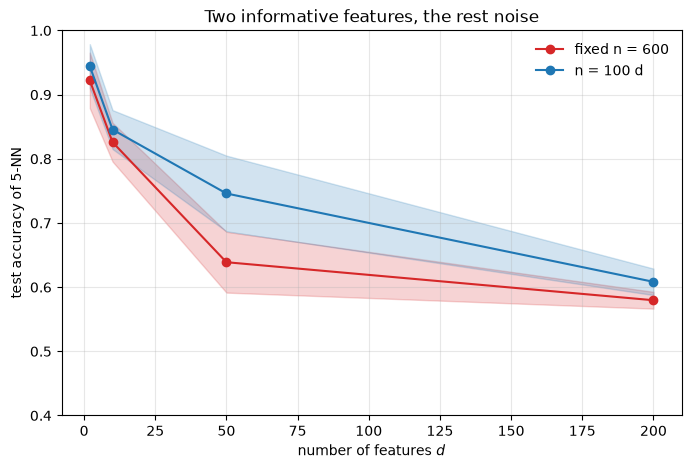

In [7]:
from sklearn.datasets import make_classification
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

dims_knn = [2, 10, 50, 200]
seeds = range(3)


def knn_accuracy(d, n_samples, seed):
    X_, y_ = make_classification(n_samples=n_samples, n_features=d, n_informative=2,
                                 n_redundant=0, n_classes=2, n_clusters_per_class=1,
                                 class_sep=1.0, flip_y=0.01, random_state=seed)
    X_tr, X_te, y_tr, y_te = train_test_split(X_, y_, test_size=0.3, random_state=seed,
                                              stratify=y_)
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
    return accuracy_score(y_te, model.fit(X_tr, y_tr).predict(X_te))


curves = {}
for label, size in [("fixed n = 600", lambda d: 600),
                    ("n = 100 d", lambda d: 100 * d)]:
    scores = np.array([[knn_accuracy(d, size(d), s) for d in dims_knn] for s in seeds])
    curves[label] = (scores.mean(axis=0), scores.std(axis=0))
    for d, mean, std in zip(dims_knn, *curves[label]):
        print(f"{label:13s} d = {d:3d}  n = {size(d):6d}   accuracy = {mean:.3f} +- {std:.3f}")

plt.figure(figsize=(8, 5))
for (label, (mean, std)), color in zip(curves.items(), ["tab:red", "tab:blue"]):
    plt.plot(dims_knn, mean, marker="o", color=color, label=label)
    plt.fill_between(dims_knn, mean - std, mean + std, color=color, alpha=0.2)
plt.xlabel("number of features $d$")
plt.ylabel("test accuracy of 5-NN")
plt.title("Two informative features, the rest noise")
plt.ylim(0.4, 1.0)
plt.legend(frameon=False)
plt.grid(alpha=0.3)
plt.show()

منحنی اول با رشد بُعد افت می‌کند هرچند ساختار آگاهی‌بخش هرگز عوض نمی‌شود: دو ویژگی سودمند هنوز
هستند ولی زیر $d-2$ ویژگی نوفه دفن شده‌اند.

منحنی دوم کمک می‌کند — در هر بُعد بهتر از نقطهٔ متناظر منحنی اول است — ولی افت را متوقف
**نمی‌کند**: دقت هنوز از حدود $0.94$ در $d=2$ به حدود $0.61$ در $d=200$ می‌افتد، با 33 برابر
دادهٔ بیشتر. دادهٔ بیشتر چگالی می‌خرد، ولی قید مقیدکننده اینجا چگالی نیست؛ این است که تقریباً همهٔ
مختصات نوفه‌اند. تمرکز فاصله خاصیتی از *توزیع* است، نه فقط از اندازهٔ نمونه.

پیامد عملی همان است که ESL در بند 2.5 می‌گیرد: برای دادهٔ با ابعاد بالا، k-NN باید پس از چیزی
بیاید که جهت‌های بی‌اطلاع را حذف یا کم‌وزن کند — انتخاب ویژگی، PCA، یا یک متریک یادگرفته.

## طرف دیگر سکه: نگاشت تصادفی و لم جانسون–لیندن‌شتراوس

همهٔ اثرهای بالا بدبینانه بودند: در ابعاد بالا فاصله‌ها متمرکز می‌شوند و «نزدیک» و «دور» یکی
می‌شوند. اما همان تمرکز روی دیگر سکه را هم نشان می‌دهد. اگر طول همهٔ بردارها تقریباً $\sqrt{d}$ و
ضرب داخلی جفت‌های تصادفی تقریباً صفر باشد، هندسهٔ داده سخت‌گیر نیست و شاید بشود آن را در بُعد
کمتری بازسازی کرد. قضیهٔ زیر همین را دقیق می‌کند و می‌گوید **نسبت فاصله‌های دوبه‌دو** با یک
نگاشت تصادفی تا خطای دلخواه $\varepsilon$ حفظ می‌شود.

### قضیهٔ 1 (جانسون–لیندن‌شتراوس)

فرض کنید $\mathbf{x}_1, \dots, \mathbf{x}_n \in \mathbb{R}^d$ و $0 < \varepsilon < 1$. اگر

$$
k \;\ge\; \frac{8 \ln n}{\varepsilon^2},
$$

آن‌گاه نگاشتی مانند $f : \mathbb{R}^d \to \mathbb{R}^k$ وجود دارد که برای **هر جفت** $i, j$

$$
(1 - \varepsilon)\, \|\mathbf{x}_i - \mathbf{x}_j\|^2
\;\le\;
\|f(\mathbf{x}_i) - f(\mathbf{x}_j)\|^2
\;\le\;
(1 + \varepsilon)\, \|\mathbf{x}_i - \mathbf{x}_j\|^2 .
$$

**خواندن قضیه.**

* بُعد هدف $k$ به $d$ بستگی ندارد و فقط با $\log n$ و $1/\varepsilon^2$ رشد می‌کند. برای $n = 1000$
  نقطه در $\mathbb{R}^d$ با $d = 10^6$ و $\varepsilon = 0.1$، عدد $k \approx 8 \times 6.9 / 0.01 \approx 5500$
  است — حدود ۱۸۰ برابر کوچک‌تر، در حالی که مجذور هیچ فاصله‌ای بیش از ۱۰٪ (و بنابراین نسبت
  طول‌ها بیش از حدود ۵٪) تغییر نمی‌کند.
* نسبت طول‌ها بین $\sqrt{1-\varepsilon}$ و $\sqrt{1+\varepsilon}$ می‌ماند، یعنی تقریباً
  $1 \pm \varepsilon/2$: رتبه‌بندی همسایه‌ها، k-NN و خوشه‌بندی تقریباً دست‌نخورده می‌مانند.
* $f$ را لازم نیست جست‌وجو کرد؛ یک **نگاشت تصادفی** کافی است. با ماتریس
  $R \in \mathbb{R}^{d \times k}$ و درایه‌های مستقل $\mathcal{N}(0,1)$،

  $$
  f(\mathbf{x}) = \frac{1}{\sqrt{k}}\, R^\top \mathbf{x},
  \qquad
  \mathbb{E}\|f(\mathbf{x})\|^2 = \|\mathbf{x}\|^2 ,
  $$

  چون برای بردار یکهٔ $\mathbf{x}$ هر مؤلفهٔ $R^\top\mathbf{x}$ مجموع $d$ جملهٔ مستقل با
  واریانس $1$ است.
* اثبات از همان تمرکزی می‌آید که دیدیم: هر طول متمرکز است، پس با نامساوی‌های چرنوف/هوفدینگ احتمال
  خطای هر جفت از مرتبهٔ $e^{-k\varepsilon^2}$ است و کران اتحاد روی $\binom{n}{2}$ جفت با
  $k = O(\log n/\varepsilon^2)$ این احتمال را زیر $1$ نگه می‌دارد.

**هزینه‌اش چیست؟** $k$ با $\varepsilon$ به‌صورت $1/\varepsilon^2$ رشد می‌کند، و قضیه چیزی دربارهٔ
«بُعد ذاتی» داده نمی‌گوید: نگاشت تصادفی فاصله‌ها را حفظ می‌کند، ولی جهت‌هایی را که داده در آن‌ها
پراکنده است پیدا نمی‌کند — این کار PCA است. به همین دلیل نگاشت تصادفی وقتی به کار می‌آید که $d$
بسیار بزرگ و PCA گران باشد، مثلاً به‌عنوان پیش‌پردازش پیش از k-NN یا k-means روی دادهٔ متنی یا
ژنومی.


## جمع‌بندی

* فضای با ابعاد بالا **در مرکز تهی** است: حجم کره در برابر مکعب ناچیز است و تقریباً همهٔ حجم مکعب
  در $2^d$ گوشهٔ آن است.
* همسایگی‌ای که نسبت ثابت $r$ از نقطه‌ها را در بر می‌گیرد یال $e_d(r) = r^{1/d}$ دارد: در ده بعد،
  10٪ داده به 80٪ دامنهٔ هر مؤلفه نیاز دارد.
* **فاصله‌ها متمرکز می‌شوند**: $d_{\min}/d_{\max} \to 1$، پس رتبه‌بندی همسایه‌ها نوفه می‌شود و
  k-NN بدتر — دادهٔ بیشتر کمک می‌کند ولی جانشین حذف ویژگی‌های بی‌اطلاع نیست.
* بیشتر حجم کره در پوستهٔ نازکی با ضخامت نسبی ثابت است، و نمونه‌های گاوسی روی شعاع $\sqrt{d}$ با
  ضخامتی که با $d$ رشد نمی‌کند متمرکز می‌شوند.
* نمودارهای بالا بدبینانه بودند، ولی **لم جانسون–لیندن‌شتراوس** روی دیگر سکه است: با
  $k = O(\log n / \varepsilon^2)$ بعد، یک نگاشت تصادفی نسبت همهٔ فاصله‌های دوبه‌دو را در بازهٔ
  $1 \pm \varepsilon/2$ نگه می‌دارد. نگاشت تصادفی فاصله‌ها را حفظ می‌کند، ولی جهت‌های مهم را
  پیدا نمی‌کند؛ آن کار PCA است.

## منابع

* {cite}`hastie2009elements`، بند 2.5 (روش‌های محلی در ابعاد بالا، شکل 2.6).
* {cite}`zaki2020data`، فصل 6 (فضای با ابعاد بالا، شکل‌های 6.4 تا 6.6).
* Blum، Hopcroft و Kannan، *Foundations of Data Science*، فصل 2 (تمرکز اندازه، تصویرهای تصادفی).